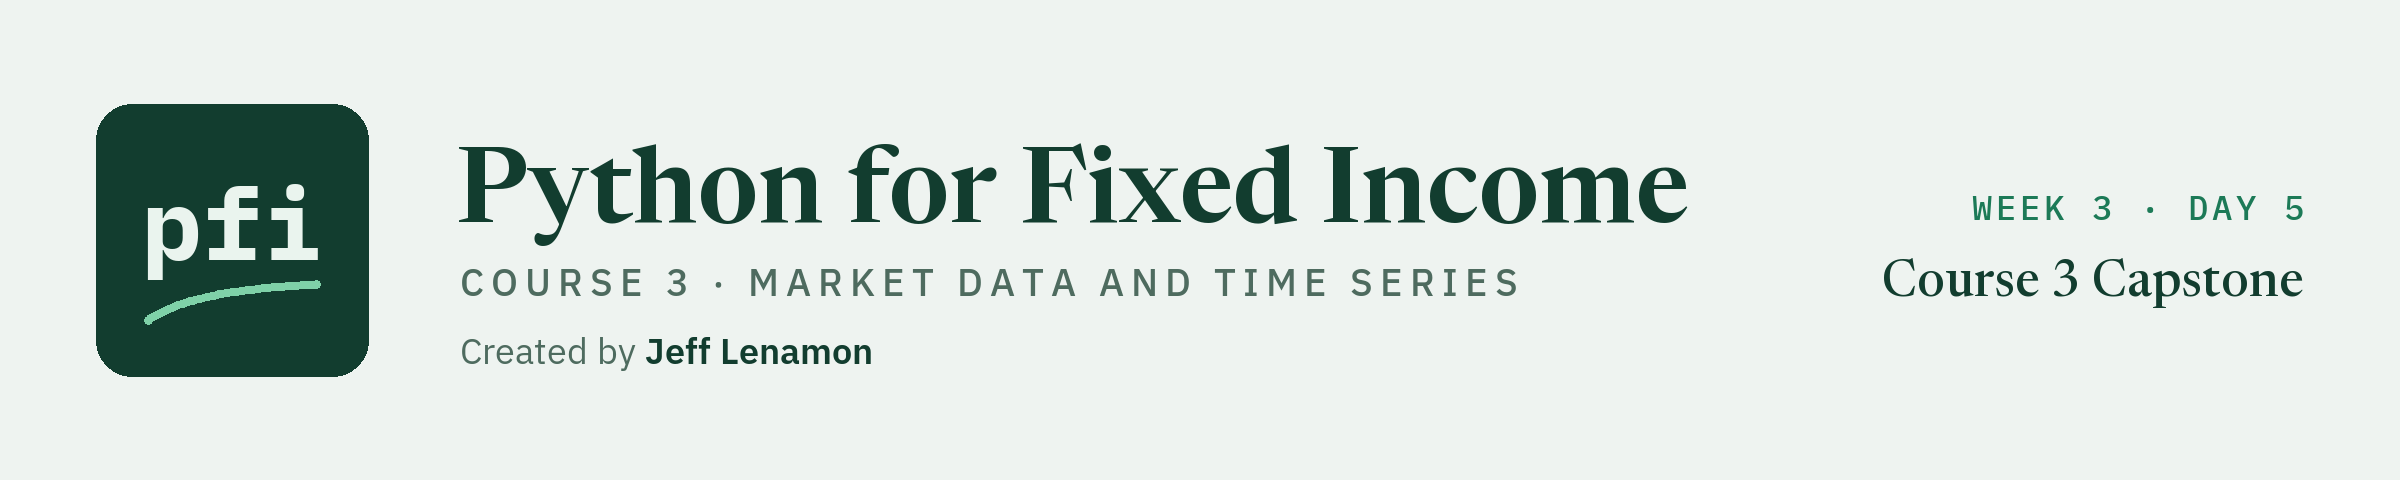

# Course 3 Capstone

Week 3, Day 5. A vendor's extract proved against its note and the market's own calendar, cleaned by one function, reconciled, appended, and turned into the snapshot for two dates. You write the code.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day5/course3_capstone.ipynb)

## The Brief

### The Desk Lead's Note

The desk lead's fifteenth note:

> The vendor's extract for July to early October is in, with a cover note. Before it touches our history, prove it against the note and the market's own calendar, fix what is wrong with a decision you can defend, and put the fixes in one function so tomorrow's file is one call. Reconcile it to the source files with nothing unexplained. Then append it and give me the snapshot for 2 October, and for 30 September from the same command. Keep both days in our database and write me one page. Describe it: no view on any rate or spread.

The file's problems are planted and unnamed.
The Treasury yields are public data; the spreads and the book are synthetic.

### The Capstone on One Page

![The capstone on one page: ten sections in three sittings. First sitting: 1 the file and its note, 2 test the extract, 3 fix the dates and the rows, 4 fix the values, ending at the checkpoint. Second sitting: 5 package it as clean_extract, deliverable 2 and a commit; 6 the reconciliation, deliverable 3. Third sitting: 7 append, then the snapshot, deliverable 4 and a commit; 8 rerun, do not redo, deliverables 5 and 6 and a commit; 9 live with your own key, optional; 10 the AI check, the log and the page, deliverables 8 and 9, a commit and the tag. Under all ten, marketdata.py as notebook 14 left it, 55 tests passing, deliverable 1. Deliverable 7 is the four commits and the tag](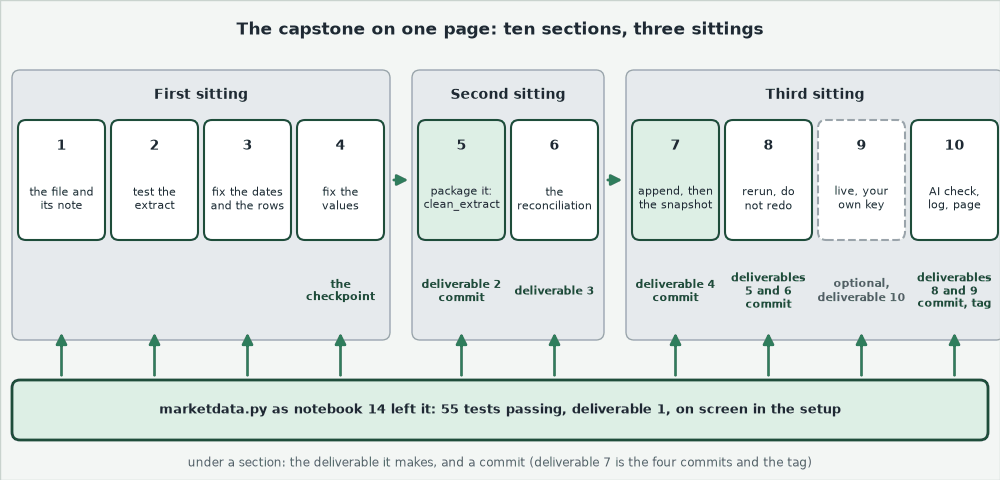)

**Ten sections, three sittings, one page at the end. Your module does the finding.**

### The Rules

1. **Work in a copy:** fixes go to `extract`, never to `raw`.
2. **State every decision** in a markdown cell, with `headline()` before and after the fix.
3. **The market calendar is the Treasury file's own dates;** never fill a value from a neighbour.
4. **Describe:** never forecast, rank, or recommend.
5. **Restart and Run All** before you hand in.

An AI assistant is allowed: the docstring is the prompt, and every answer is tested and logged in 10.2.

### How It Is Checked

Each `check()` compares a fingerprint of your answer with a stored one; round as each question asks.
The checkpoint must pass before section 5.
A Stuck block holds the expected decision: open it after your own.

## The Data

Units: yields in percent, spreads in basis points, the book in dollars.

<table align="left">
<tr><th align="left">File</th><th align="left">What it is</th></tr>
<tr><td align="left"><code>course3_capstone_extract.csv</code></td><td align="left">the vendor's extract, read as text</td></tr>
<tr><td align="left"><code>course3_capstone_cover_note.txt</code></td><td align="left">the vendor's note</td></tr>
<tr><td align="left"><code>treasury_par_yields.csv</code></td><td align="left">the Treasury par curve</td></tr>
<tr><td align="left"><code>course3_synthetic_spreads.csv</code></td><td align="left">two synthetic spreads</td></tr>
<tr><td align="left"><code>holdings.csv</code></td><td align="left">the September book, synthetic</td></tr>
</table>
<br clear="left">

The clean history ends at `HISTORY_END`, 2026-06-30.
The Treasury file and the spreads run on past it: the course holds the extract's clean twin, so every decision can be proved.

## Setup

Run these cells first and do not change them.

### Today's Work Folder

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 14 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(15)

Work folder pfi_course3_15_k4w7q2xr: 10 data files, Course 2's bondmath.py, marketdata.py as notebook 14 left it, 14 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................................                  [100%]
55 passed in 0.50s



**Deliverable 1 is on screen: 55 tests pass.**

### Imports and the Files

In [3]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module as notebook 14 left it, in the work folder
import marketdata as md

In [4]:
# raw is the extract exactly as it arrived, every cell read as text
raw = pd.read_csv('course3_capstone_extract.csv', dtype=str)
# source: the Treasury file (percent) joined to the synthetic spreads (bp), as in notebook 14
options = {'parse_dates': ['date'], 'index_col': 'date', 'float_precision': 'round_trip'}
source = pd.read_csv('treasury_par_yields.csv', **options).join(
    pd.read_csv('course3_synthetic_spreads.csv', **options), validate='one_to_one')
september = pd.read_csv('holdings.csv')

In [5]:
# the vendor's cover note, as it came
print(Path('course3_capstone_cover_note.txt').read_text(encoding='utf-8'))

To: Credit desk
From: Market data vendor, client operations
Subject: Daily extract, 2026-07-01 to 2026-10-02

The extract is attached as course3_capstone_extract.csv, in the usual layout.

Period:        2026-07-01 to 2026-10-02
Market days:   66
Columns:       date, 2 Yr, 5 Yr, 10 Yr, 30 Yr (par yields, percent), ig_spread_bp, hy_spread_bp (basis points)

Last values sent, for 2026-10-02:
  2 Yr     4.83 percent
  5 Yr     5.06 percent
  10 Yr    5.28 percent
  30 Yr    5.63 percent
  ig_spread_bp   97.0
  hy_spread_bp   328.7

The spread columns are synthetic course data, invented for this course. They are not ICE, Moody's, or any index.
Please tell us if the extract does not agree with these figures.



In [6]:
# the cover note's figures, typed in, and the last day of the clean history
NOTE_DAYS = 66
NOTE_LAST = {'2 Yr': 4.83, '5 Yr': 5.06, '10 Yr': 5.28, '30 Yr': 5.63,
             'ig_spread_bp': 97.0, 'hy_spread_bp': 328.7}
VALUE_COLUMNS = list(NOTE_LAST)
YIELDS, SPREADS = VALUE_COLUMNS[:4], VALUE_COLUMNS[4:]
HISTORY_END = '2026-06-30'


def headline(label, table):
    # rows, and cells with no number ('.' as sent, or NaN once read), before and after every fix
    empty = int((table == '.').sum().sum() + table.isna().sum().sum())
    print(f'{label}: {len(table)} rows, {empty} cells with no number')

### `check()`

In [7]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

### Where the Extract Sits

Q. Where does the extract's period fall in the clean history?

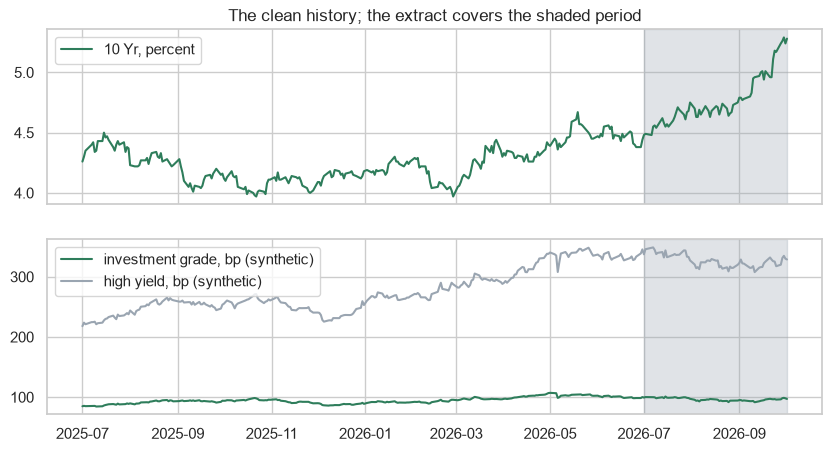

In [8]:
# the clean history from July 2025: the 10 Yr in percent, the two synthetic spreads in bp
recent = source.loc['2025-07-01':]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
top.plot(recent.index, recent['10 Yr'], label='10 Yr, percent')
bottom.plot(recent.index, recent['ig_spread_bp'], label='investment grade, bp (synthetic)')
bottom.plot(recent.index, recent['hy_spread_bp'], label='high yield, bp (synthetic)')
for ax in (top, bottom):
    # notebook 03's shaded band: the days after HISTORY_END, the extract's period
    ax.axvspan(pd.Timestamp('2026-07-01'), recent.index[-1], color='#9AA5B1', alpha=0.3)
    ax.legend(loc='upper left')
top.set_title('The clean history; the extract covers the shaded period')
plt.show()

**The clean history stops in June; the extract must earn its place after it.**

## 1 The File and Its Note

**Predict 1**

Q. The cover note promises 66 market days. How many rows does the file hold? Write down a number.

### 1.1 Rows, Columns, and a Working Copy

Q. What shape is `raw` (**answer_1_1**)? Copy it to `extract`.

In [9]:
# your code here
extract = ...
answer_1_1 = ...

check('Question 1.1', answer_1_1, 'cefd585c57fa')

Question 1.1: not attempted yet


### 1.2 The File Against Its Note

Q. Print `headline()` as received. How many rows beyond the note's market days (**answer_1_2a**)? Are the columns in the note's order? How many of the last row's six values differ from the note (**answer_1_2b**)?

In [10]:
# your code here
answer_1_2a = ...
answer_1_2b = ...

check('Question 1.2 rows', answer_1_2a, '34bb5cef5d6e', places=0)
check('Question 1.2 last row', answer_1_2b, 'f7c08b799c65', places=0)

Question 1.2 rows: not attempted yet
Question 1.2 last row: not attempted yet


**The last row matches the note; the row count does not.**

## 2 Test the Extract

Seven rules say what a clean extract looks like.
Count on `extract` as 1.1 made it, and fix nothing until section 3.

<table align="left">
<tr><th align="left">Rule</th><th align="left">What the desk expects</th></tr>
<tr><td align="left">1</td><td align="left">one row per market day, no row a copy</td></tr>
<tr><td align="left">2</td><td align="left">every date written <code>YYYY-MM-DD</code></td></tr>
<tr><td align="left">3</td><td align="left">every date a market day</td></tr>
<tr><td align="left">4</td><td align="left">every market day a row</td></tr>
<tr><td align="left">5</td><td align="left">no value missing</td></tr>
<tr><td align="left">6</td><td align="left">the note's units: yields in percent, spreads in bp</td></tr>
<tr><td align="left">7</td><td align="left">no value stuck for 5 rows in a row</td></tr>
</table>
<br clear="left">

Tools: Course 1's `pd.to_datetime(errors='coerce')`, `duplicated()` and `isin()`.

**Excel side by side.** The extract pasted as text into A1:G70; tested in desktop Excel for Windows.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">A date read as <code>YYYY-MM-DD</code></td><td align="left"><code>format='%Y-%m-%d', errors='coerce'</code></td><td align="left"><code>=DATE(LEFT(A2,4),MID(A2,6,2),RIGHT(A2,2))</code></td></tr>
<tr><td align="left"><code>.</code> read as no value</td><td align="left"><code>== '.'</code></td><td align="left"><code>=IFERROR(VALUE(B2),NA())</code></td></tr>
<tr><td align="left">A 5 Yr yield above 25</td><td align="left"><code>&gt; 25</code></td><td align="left"><code>=IFERROR(VALUE(C2),NA())&gt;25</code></td></tr>
<tr><td align="left">A spread below 10</td><td align="left"><code>&lt; 10</code></td><td align="left"><code>=IFERROR(VALUE(F2),NA())&lt;10</code>, <code>=IFERROR(VALUE(G2),NA())&lt;10</code></td></tr>
</table>
<br clear="left">

### 2.1 Rule 2: Dates

Q. How many dates do not read as `YYYY-MM-DD` (**answer_2_1**)? Show them as written.

<details><summary>Stuck? The expected decision</summary>

Read each date in the form it was written: `YYYY-MM-DD`, else `MM/DD/YYYY`.

</details>

In [11]:
# your code here
answer_2_1 = ...

check('Question 2.1', answer_2_1, '215a68538e6a', places=0)

Question 2.1: not attempted yet


### 2.2 Rule 5: No Value Missing

Q. How many cells hold `.` (**answer_2_2a**), and in how many rows (**answer_2_2b**)? Show those rows.

<details><summary>Stuck? The expected decision</summary>

`.` is a missing value, never 0.

A row with every value missing goes, if the market had no curve that day.

</details>

In [12]:
# your code here
answer_2_2a = ...
answer_2_2b = ...

check('Question 2.2 cells', answer_2_2a, '4abbf26e8942', places=0)
check('Question 2.2 rows', answer_2_2b, 'd541498f8e00', places=0)

Question 2.2 cells: not attempted yet
Question 2.2 rows: not attempted yet


### 2.3 Rule 1: Copies

Q. How many rows are exact copies of an earlier row (**answer_2_3**)? Show each.

<details><summary>Stuck? The expected decision</summary>

Remove each exact copy, keeping the first.

</details>

In [13]:
# your code here
answer_2_3 = ...

check('Question 2.3', answer_2_3, '6cc3d22a07c7', places=0)

Question 2.3: not attempted yet


### 2.4 Rule 6: Units

Q. Read the values as numbers, `.` left out. How many yields are above 25 (**answer_2_4a**), and how many spreads below 10 (**answer_2_4b**)? Show them.

<details><summary>Stuck? The expected decision</summary>

A yield above 25 was sent in bp: divide by 100, to 2 decimals.

A spread below 10 was sent in percent: multiply by 100, to 1 decimal.

</details>

In [14]:
# your code here
answer_2_4a = ...
answer_2_4b = ...

check('Question 2.4 yields', answer_2_4a, 'b17155d3a41a', places=0)
check('Question 2.4 spreads', answer_2_4b, 'defac6353129', places=0)

Question 2.4 yields: not attempted yet
Question 2.4 spreads: not attempted yet


## 3 Fix the Dates and the Rows

Dates first: every other rule needs them.
Tools: Course 1's `.fillna()` and `drop_duplicates()`, notebook 03's `md.missing_weekdays`.

### 3.1 Dates and Copies

Q. Read every date in the form it was written, then remove the exact copies. How many rows are left (**answer_3_1**)?

In [15]:
# your code here: a decision cell, then the fix with headline() before and after
answer_3_1 = ...

check('Question 3.1', answer_3_1, '5d876ff26f3b', places=0)

Question 3.1: not attempted yet


### 3.2 The Row of Dots

Q. One row holds `.` in every value. Give its date as text year-month-day (**answer_3_2a**), and whether `source` has a row for it, `True` or `False` (**answer_3_2b**). Decide and fix.

In [16]:
# your code here
answer_3_2a = ...
answer_3_2b = ...

check('Question 3.2 date', answer_3_2a, '1f4a71c62771')
check('Question 3.2 market day', answer_3_2b, 'c3275e2fd133')

Question 3.2 date: not attempted yet
Question 3.2 market day: not attempted yet


### 3.3 Rules 3 and 4: The Market's Own Days

Q. Test the dates against `source`'s: give the date that is not a market day (**answer_3_3a**) and the market day with no row (**answer_3_3b**), as text. `md.missing_weekdays(...).intersection(source.index)` finds the second.

<details><summary>Stuck? The expected decision</summary>

Drop the first.

Restore the second in 4.3, from `source`: a value filled from a neighbour is one the market never printed.

</details>

In [17]:
# your code here
answer_3_3a = ...
answer_3_3b = ...

check('Question 3.3 not a market day', answer_3_3a, 'ba83ab38c9d9')
check('Question 3.3 no row', answer_3_3b, '02f18fb7688d')

Question 3.3 not a market day: not attempted yet
Question 3.3 no row: not attempted yet


## 4 Fix the Values

Tools: Course 1's `.loc[mask, column] =`, notebook 03's `md.stale_runs` and `pd.concat`.

### 4.1 Rule 6: Units

Q. Set the dates as the index and read the values as floats. Fix the units by 2.4's thresholds. Give the largest yield (**answer_4_1a**) and the smallest spread (**answer_4_1b**) after the fix.

In [18]:
# your code here: a decision cell, then the fix with headline() before and after
answer_4_1a = ...
answer_4_1b = ...

check('Question 4.1 largest yield', answer_4_1a, '7be835931457', places=2)
check('Question 4.1 smallest spread', answer_4_1b, 'dbda7fa3888a', places=1)

Question 4.1 largest yield: not attempted yet
Question 4.1 smallest spread: not attempted yet


### 4.2 Rule 7: A Stale Run

Q. Run `md.stale_runs(..., min_length=5)` on each column. Which column has a run (**answer_4_2a**), and on what date does it start, as text (**answer_4_2b**)?

<details><summary>Stuck? The expected decision</summary>

The first value stands; each repeat comes from `source`.
Only the clean twin makes that possible: a real vendor is asked to send the values again.

</details>

In [19]:
# your code here
answer_4_2a = ...
answer_4_2b = ...

check('Question 4.2 column', answer_4_2a, '70e70314111f')
check('Question 4.2 start', answer_4_2b, '8a48f423d4cb')

Question 4.2 column: not attempted yet
Question 4.2 start: not attempted yet


### 4.3 Restore From the Source

Q. Restore the repeats and the missing market day from `source`, sort by date, and `assert` the dates equal the period's market days in `source`. Give the restored day's 10 Yr (**answer_4_3**).

In [20]:
# your code here
answer_4_3 = ...

check('Question 4.3', answer_4_3, '3df58e7128c1', places=2)

Question 4.3: not attempted yet


### Checkpoint: The Cleaned Extract

Q. Does `extract` match `source` and the expected decisions? Every line must read `correct` before section 5.

In [21]:
# the cleaned extract against the source files and the decisions the worked version made
if extract is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(extract), '4d3783af28ef', places=0)
    check('Checkpoint first date', f'{extract.index[0]:%Y-%m-%d}', 'bd218fac6b48')
    check('Checkpoint last date', f'{extract.index[-1]:%Y-%m-%d}', '9a51dd8ab64d')
    check('Checkpoint missing values', extract.isna().sum().sum(), '3117f3c606c8', places=0)
    gap = (extract - source.loc[extract.index, VALUE_COLUMNS]).abs().max().max()
    check('Checkpoint gap from source', gap, '8b80901df176', places=9)
    check('Checkpoint mean 5 Yr', extract['5 Yr'].mean(), '865b6d2992f1', places=3)
    check('Checkpoint mean hy', extract['hy_spread_bp'].mean(), '8ea3cb50eb1d', places=3)
    check('Checkpoint raw is unchanged', raw.shape, 'd0733f5fa2a6')

Checkpoint: not attempted yet


**The extract now equals the source on every market day. The first sitting ends here.**

## 5 Package It

### 5.1 `clean_extract`, Docstring First

Q. In `clean_extract.py`, written with `%%writefile` in a cell of its own, write `clean_extract(raw, source)`: a docstring listing your seven decisions, then the decisions in that order, its inputs unchanged.
It returns `(cleaned, log)`, `log` one row per change: `date`, `column` (`all` for a whole row), `received`, `cleaned`, `decision`.
`assert` each rule it promises, with a message.
Store its result on `raw` in **cleaned** and **log**, and `assert` the note's market days and last values.

In [22]:
# your code here: start this cell with %%writefile clean_extract.py

In [23]:
# your code here
cleaned = ...
log = ...

if cleaned is ...:
    print('Question 5.1: not attempted yet')
else:
    check('Question 5.1 rows', len(cleaned), '61ed9e1e2e21', places=0)
    check('Question 5.1 same as extract', cleaned.equals(extract), '288c3cca9e6d')
    check('Question 5.1 log lines', len(log), '9f174ecd8344', places=0)
    check('Question 5.1 raw is unchanged', raw.shape, '99d973544a52')

Question 5.1: not attempted yet


### As Received Against Cleaned

Written for you, and drawn once `cleaned` exists: the file's numbers as sent against `cleaned`.
A value far outside the cleaned range sits on its panel's edge.

In [24]:
# written for you: each column as received (grey points) against cleaned (green line)
if cleaned is not ...:
    # the dates written YYYY-MM-DD; the three month-first rows are left out, their values clean
    dates = pd.to_datetime(raw['date'], format='%Y-%m-%d', errors='coerce')
    fig, axes = plt.subplots(6, 1, figsize=(10, 9), sharex=True)
    for ax, column in zip(axes, VALUE_COLUMNS):
        # clip(low, high), Course 1's clip at both ends: a value sent far off sits on the edge
        low, high = cleaned[column].min() * 0.97, cleaned[column].max() * 1.03
        sent = pd.to_numeric(raw[column], errors='coerce').clip(low, high)
        ax.scatter(dates, sent, s=14, color='#9AA5B1')
        ax.plot(cleaned.index, cleaned[column], color='#2E7D5B')
        ax.set_ylabel(column)
    plt.show()

### 5.2 Commit It

Q. Commit `clean_extract.py` alone, with a subject naming the deliverable, and show the history.

**One call rebuilds the cleaned extract from the file as it arrived.**

In [25]:
# your Git commands here, each written !git -C "{work}" ...

## 6 The Reconciliation

![A difference meets the log. On the left, a row of differences: date, column, received, source. On the right, a row of the log: date, column, received, cleaned, decision. They join on two keys, date and column, with validate many_to_one: many differences may share one log line, and each log key is unique. A difference that finds its line carries the decision. One that finds none reads unexplained, a dashed box, and the goal is that nothing reaches it](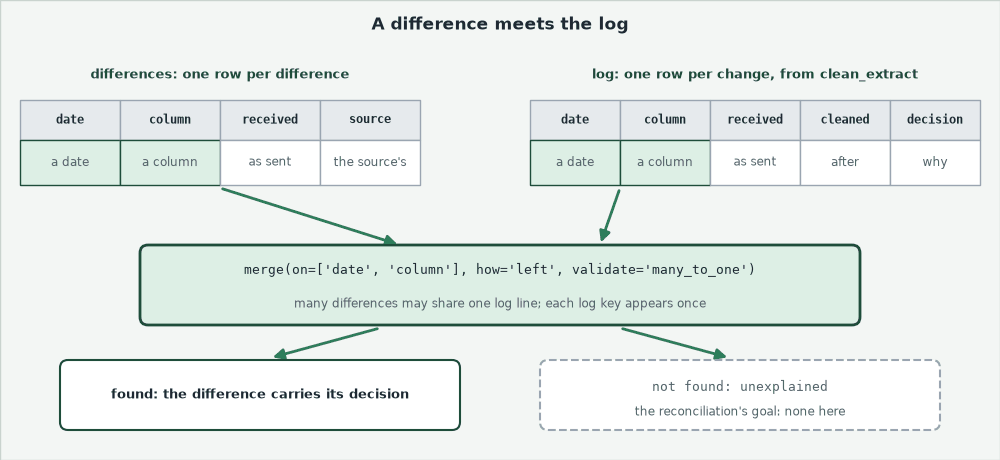)

A **reconciliation** sets the file as received beside the source files and gives every difference a decision from `log`.

### 6.1 The File Against the Source

Q. Read `raw`'s dates in both forms and fix nothing else. Build **differences** (`date` as text, `column`, `received`, `source`): a row per extra copy, per row on a day with no market, per market day with no row (column `all`), and per value that differs from `source`. How many (**answer_6_1**)?

In [26]:
# your code here
differences = ...
answer_6_1 = ...

check('Question 6.1', answer_6_1, '3457608b9905', places=0)

Question 6.1: not attempted yet


### 6.2 A Decision for Every Difference

Q. Merge `differences` with `log` on `date` and `column`, `validate='many_to_one'`, as **explained**. How many have no decision (**answer_6_2a**), and how many decisions do they use (**answer_6_2b**)?

In [27]:
# your code here
explained = ...
answer_6_2a = ...
answer_6_2b = ...

check('Question 6.2 unexplained', answer_6_2a, '127b5cf28a78', places=0)
check('Question 6.2 decisions', answer_6_2b, '49c249660466', places=0)

Question 6.2 unexplained: not attempted yet
Question 6.2 decisions: not attempted yet


### Every Difference by Its Decision

Written for you: which decision covers the most differences?

In [28]:
# written for you: each decision's differences, split by column (Course 1's crosstab)
if explained is ...:
    print('Chart: not attempted yet')
else:
    by_decision = pd.crosstab(explained['decision'], explained['column'])
    ax = by_decision.plot.barh(stacked=True, figsize=(9, 4))
    ax.set_title('Every Difference Has a Decision')
    ax.set_xlabel('Differences from the source files')
    ax.set_ylabel('Decision in the log')
    ax.legend(title='Column')
    plt.show()

Chart: not attempted yet


**Every difference has a decision behind it. The second sitting ends here.**

## 7 Append, Then the Snapshot

![History, then the extract. The top band is the clean history from 2015-01-02 to HISTORY_END, 2026-06-30: fourteen Treasury tenors and two synthetic spreads. The band beside it is the cleaned extract from 2026-07-01 to 2026-10-02: four tenors, 2 Yr, 5 Yr, 10 Yr and 30 Yr, and the two spreads, with the other ten tenors empty. pd.concat stacks them into one table, market. snapshot_tables reads market.loc up to the as-of date](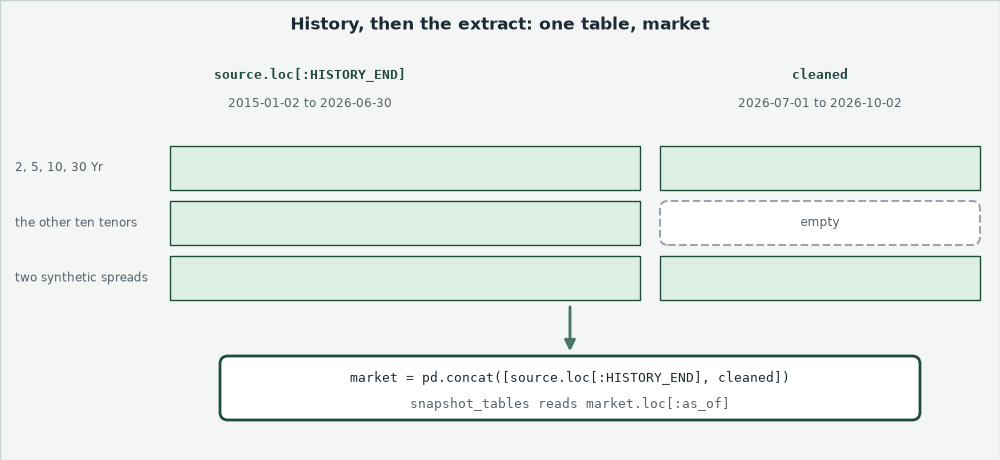)

The third sitting: the cleaned extract joins the history, and notebook 14's snapshot runs on it.

### 7.1 The Appended Market

Q. Make **market**: `source` up to `HISTORY_END`, then `cleaned`, with `pd.concat`. `assert` its dates are unique and ascending, and that its six columns equal `source`'s with notebook 10's `assert_frame_equal(check_exact=True)`. Give its rows (**answer_7_1**).

In [29]:
# your code here
market = ...
answer_7_1 = ...

check('Question 7.1', answer_7_1, '471d9de65069', places=0)

Question 7.1: not attempted yet


**Predict 2**

Q. The extract carries no 3 Mo yield, so after June `market` has none. On `market`, `md.snapshot_tables` for 2 October shows 3m10y as:

A) no row
B) a row with no level
C) a row with June's last level, its week and month changes zero

### 7.2 The Snapshot for 2 October

Q. Build **tables** with `md.snapshot_tables(market, september, '2026-10-02', units)`, `units` as notebook 14's. How many tenors does the curve have (**answer_7_2a**)? Give the 3m10y level, to 1 place (**answer_7_2b**). From what date is it?

<details><summary>Stuck? The expected decision</summary>

A slope or fly whose tenors have no value on the date is dropped, and a fifth table, `notes`, says so.

</details>

In [30]:
# your code here
tables = ...
answer_7_2a = ...
answer_7_2b = ...

check('Question 7.2 tenors', answer_7_2a, '16ca53503dc3', places=0)
check('Question 7.2 3m10y', answer_7_2b, '6303ca0db272', places=1)

Question 7.2 tenors: not attempted yet
Question 7.2 3m10y: not attempted yet


**Predict 3**

Q. Same book, same day, and the four tenors equal the Treasury file's. Notebook 14's what-if on the whole curve was -1,193,297.89 dollars. On `market`'s four tenors it is:

A) the same
B) smaller in size
C) larger in size

### 7.3 The Book on Four Tenors

Q. Give the book's what-if (**answer_7_3a**) and DV01 in dollars per bp (**answer_7_3b**), to 2 places. Every yield it reads is the Treasury file's: why does it differ?

In [31]:
# your code here
answer_7_3a = ...
answer_7_3b = ...

check('Question 7.3 what-if', answer_7_3a, '577abdf89bfa', places=2)
check('Question 7.3 DV01', answer_7_3b, '0b506ae3c452', places=2)

Question 7.3 what-if: not attempted yet
Question 7.3 DV01: not attempted yet


### 7.4 `snapshot.py`, Rewritten

Q. Rewrite notebook 14's `snapshot.py` with `%%writefile`.
`load_market()` appends the extract, cleaned by `clean_extract`, to the history.
`daily_snapshot(market, book, as_of)` drops each shape with a tenor empty on the date, and adds a table `notes`, column `note`: the curve's tenors, the shapes not shown, the what-if as a what-if, the spreads as synthetic.
`main()` calls it; nothing else changes.
Import it, and give the shapes it leaves out for 2 October, as a list (**answer_7_4**).

In [32]:
# your code here: start this cell with %%writefile snapshot.py

In [33]:
# your code here
answer_7_4 = ...

check('Question 7.4', answer_7_4, '5647e31242a5')

Question 7.4: not attempted yet


### Read the Diff, Then Commit

Q. Read `git diff --stat` and `git diff snapshot.py`, then commit `snapshot.py`.

**The snapshot says what it cannot show, and the script that writes it is in the record.**

In [34]:
# your Git commands here, each written !git -C "{work}" ...

## 8 Rerun, Do Not Redo

![One command, two dates, one table. python snapshot.py --as-of 2026-10-02 and --as-of 2026-09-30 each write a page and a workbook into snapshots. The two levels sheets are stacked, each row with its as_of date, into snapshot_history in course3.db. A SQL query and its pandas twin meet at md.assert_same_rows](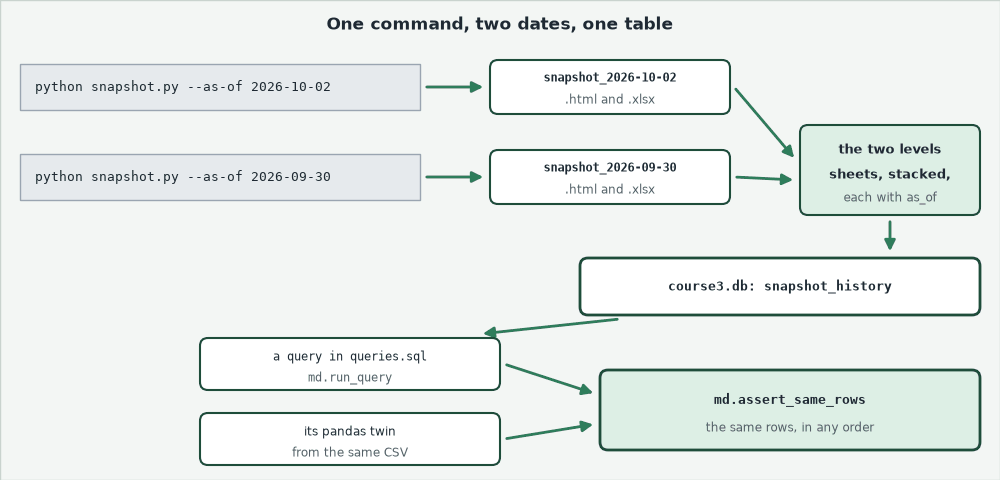)

### 8.1 Two Dates, One Command

Q. Run `snapshot.py --as-of 2026-10-02`, then `--as-of 2026-09-30`, with `subprocess`; `assert` each exit code is 0. Read the 2 October page back: its date line, `md.DISCLAIMER`, "synthetic", its tables. Give the 30 September workbook's sheet names, as a list (**answer_8_1a**), and its 10 Yr level (**answer_8_1b**).

**Excel side by side.** The script's workbook in desktop Excel for Windows, values with no formulas; tested there.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Each tenor's change on <code>curve</code></td><td align="left"><code>chg_bp</code></td><td align="left"><code>=(D2-C2)*100</code>, filled down</td></tr>
<tr><td align="left">The book's DV01 and what-if from its sector rows</td><td align="left">the <code>total</code> row</td><td align="left"><code>=SUMIFS(G:G,B:B,"sector")</code>, <code>=SUMIFS(H:H,B:B,"sector")</code></td></tr>
</table>
<br clear="left">

In [35]:
# your code here
answer_8_1a = ...
answer_8_1b = ...

check('Question 8.1 sheets', answer_8_1a, 'bd746f2eb678')
check('Question 8.1 10 Yr', answer_8_1b, '485231e5ab23', places=2)

Question 8.1 sheets: not attempted yet
Question 8.1 10 Yr: not attempted yet


### 8.2 The Two Levels Side by Side

Q. Set the two workbooks' `levels` sheets side by side as **two_dates**, with a column `change_bp`: 2 October less 30 September, yields times 100, spreads as they are. Which series moved most in size (**answer_8_2**)?

In [36]:
# your code here
two_dates = ...
answer_8_2 = ...

check('Question 8.2', answer_8_2, '4ba52149e161')

Question 8.2: not attempted yet


### Two Dates, Six Series

Written for you: how each series moved between the two dates.

In [37]:
# written for you: each series' change from 30 September to 2 October, in bp, signed
if two_dates is ...:
    print('Chart: not attempted yet')
else:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.barh(two_dates.index, two_dates['change_bp'])
    ax.axvline(0, color='#1E4D3A', linewidth=1)
    ax.bar_label(bars, fmt='{:+.1f}', padding=3)
    # room on both sides for the labels
    ax.set_xlim(two_dates['change_bp'].min() - 1.5, two_dates['change_bp'].max() + 1.5)
    ax.set_title('2 October Against 30 September, One Command Each')
    ax.set_xlabel('Change (bp)')
    plt.show()

Chart: not attempted yet


### 8.3 Both Days in the Database

Q. Stack the two `levels` sheets, each row with its date as `as_of`, into `snapshot_history.csv` (`as_of`, `series`, `unit`, `level`), and load it into `course3.db` with `md.load_tables`.
Append two queries to `queries.sql` with `%%writefile -a`: one series by a `?` parameter, and each series' change in bp with notebook 12's `LAG(level) OVER (PARTITION BY series ORDER BY as_of)` and `CASE WHEN`.
Check each against pandas with `md.assert_same_rows`.
Give the rows (**answer_8_3a**) and SQL's high yield change, to 1 place (**answer_8_3b**).

In [38]:
# your code here
answer_8_3a = ...
answer_8_3b = ...

check('Question 8.3 rows', answer_8_3a, '386f170975c2', places=0)
check('Question 8.3 change', answer_8_3b, 'e1e01769952b', places=1)

Question 8.3 rows: not attempted yet
Question 8.3 change: not attempted yet


### 8.4 A Test, Then Commit

Q. Write `test_capstone.py`: `test_clean_extract_ties_to_the_cover_note` (66 market days, the six last values) and `test_market_equals_source` (`snapshot.load_market()` against `source`).
The pytest cell below runs `test_marketdata.py` alone: add `'test_capstone.py',` before it in the command, and run the cell again.
Give the count passed (**answer_8_4**), check `course3.db` is ignored with `git check-ignore -v`, and commit `queries.sql` and `test_capstone.py`.

In [39]:
# your code here: start this cell with %%writefile test_capstone.py

In [40]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................................                  [100%]
55 passed in 0.50s



In [41]:
# your code here, then your Git commands, each written !git -C "{work}" ...
answer_8_4 = ...

check('Question 8.4', answer_8_4, '57a80ea3b287', places=0)

Question 8.4: not attempted yet


**Both days are in SQL, and a test says the market equals its sources.**

## 9 Live, With Your Own Key (Optional)

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

### Your Key

In [42]:
from pathlib import Path

# your .env file: in my_bondmath, outside every repository. The key cell looks here last.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# what every live cell prints when no key was found
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen; set True only on your own machine
SHOW_LICENSED_VALUES = False

In [43]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


### The Four Tenors From FRED

In [44]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    # the extract's four tenors from FRED for its period, in percent, the empty days dropped
    live_ids = {'DGS2': '2 Yr', 'DGS5': '5 Yr', 'DGS10': '10 Yr', 'DGS30': '30 Yr'}
    live_curve = pd.DataFrame({live_column: md.fred_series(live_id, fred_key, start='2026-07-01',
                                                           end='2026-10-02')
                               for live_id, live_column in live_ids.items()}).dropna()
    # the check: FRED equals source on every date both have, as cleaned does
    live_common = live_curve.index.intersection(source.index)
    live_gap = (live_curve.loc[live_common] - source.loc[live_common, YIELDS]).abs().max().max()
    assert len(live_common) > 0 and live_gap <= 1e-9, 'FRED and the source files disagree'
    print(f'{len(live_common)} dates in both, largest gap {live_gap:.1e} percent')

Live cell skipped: no FRED key was found. Every other cell runs without one.


### The Licensed Series, Metadata Only

In [45]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    # licensed series: metadata only, values only under SHOW_LICENSED_VALUES (False here)
    for live_id in ['BAMLC0A0CM', 'BAMLH0A0HYM2', 'BAA10Y']:
        live_series = md.fred_series(live_id, fred_key)
        live_weekend = int((live_series.index.dayofweek >= 5).sum())
        print(f'{live_id}: percent, {len(live_series):,} rows, {live_series.index[0]:%Y-%m-%d} to '
              f'{live_series.index[-1]:%Y-%m-%d}, {int(live_series.isna().sum())} . rows, '
              f'{live_weekend} weekend rows')
        assert len(live_series) > 0, f'{live_id} came back empty'
        if SHOW_LICENSED_VALUES:
            print((live_series.dropna().tail(5) * 100).round(1).to_string())

Live cell skipped: no FRED key was found. Every other cell runs without one.


The saved run had no key, so both print the skip message.
With a key, the first prints the dates FRED and the source files share, and a gap of zero.
The second prints each licensed series' rows and dates, never a value: the snapshot uses the synthetic spreads because it is shared.

## 10 The Deliverables

### 10.1 The AI Check

You asked an assistant for one step of `clean_extract`, the docstring as the prompt.
This came back, written for this course in an assistant's style: it runs, and it breaks one rule of the brief.

In [46]:
def complete_days(extract, source):
    """Give the extract one row for every market day of its period, and no other row.

    extract: dates as its index and the six value columns, the holiday and weekend rows already
    dropped. source: the clean history, whose dates are the market calendar. A market day the
    extract lacks is taken from source, never filled from a neighbour: a filled value is one the
    market never printed, and it makes a change of zero. Returns a new table; extract is unchanged.
    """
    # every weekday of the period, then carry the last value forward into any gap
    days = pd.bdate_range(extract.index[0], extract.index[-1], name='date')
    return extract.reindex(days).ffill()

**Predict 4**

The test data is `source`'s 66 market days from 1 July to 2 October, with 26 August taken out: 65 rows.

Q. How many rows will the assistant's version return? Write down a number.

### Run It, Then Test It

Q. Run it on the test data, then test it against the market calendar before you trust it.

In [47]:
# the test data: the source's market days of the period, and the same with one taken out
test_days = source.loc['2026-07-01':'2026-10-02', VALUE_COLUMNS]
test_input = test_days.drop(pd.Timestamp('2026-08-26'))
completed = complete_days(test_input, source)
print(f'{len(test_input)} rows in, {len(completed)} rows returned')
# the dates must be the market calendar, and every value the source's
extra = completed.index.difference(test_days.index)
missing = test_days.index.difference(completed.index)
assert extra.empty and missing.empty, (f'{len(extra)} dates that are not market days, '
                                       f'{len(missing)} market days missing')
assert (completed - test_days).abs().max().max() <= 1e-9, 'a value differs from the source'
print("The market days of the period, every value the source's")

65 rows in, 68 rows returned


AssertionError: 2 dates that are not market days, 0 market days missing

Q. Find the rule it broke, fix it in its defining cell, and rerun until the test passes. Give the rows the assistant's version added that are not market days (**ai_added_rows**), and your version's rows (**ai_rows_fixed**).

In [48]:
# your code here
ai_added_rows = ...
ai_rows_fixed = ...

check('AI check rows added', ai_added_rows, '8dd6869decc0', places=0)
check('AI check rows fixed', ai_rows_fixed, 'f81698e32501', places=0)

AI check rows added: not attempted yet
AI check rows fixed: not attempted yet


### 10.2 The AI-Use Log

Q. Write one row per question you asked an AI assistant; `none used` is valid. Run the cell to write `ai_use_log.md`.

Nothing from an employer, no key, and no licensed data goes into an AI tool or Colab; your firm's policy comes first.

In [49]:
%%writefile ai_use_log.md
# AI-use log

| What I asked | What I kept or rejected | How I checked it |
| --- | --- | --- |
| | | |
| | | |

Writing ai_use_log.md


### 10.3 The Page

Q. Write the page for the desk lead, 300 to 450 words, in five parts:

* the levels on both dates, with units;
* the changes to 2 October over a day, a week and a month;
* where each series sits in its year;
* the book's DV01 and what-if;
* the data: each problem, its rows, its decision.

Describe, never forecast.

Run the cell to write `description.md`.

In [50]:
%%writefile description.md
# Two market days: 2026-09-30 and 2026-10-02

Write your page here, then run this cell.

Writing description.md


### The Words Test

`assert_descriptive` stops on a word that forecasts or advises.
The list is a reminder, not a proof: a sentence can forecast without any of them.

In [51]:
import re

# words that forecast or advise, from notebook 08's describe-or-forecast table and more
FORECAST_WORDS = ['will', 'expect', 'expects', 'expected', 'should', 'cheap', 'rich', 'attractive',
                  'signal', 'buy', 'sell', 'likely', 'outlook', 'recommend', 'overweight',
                  'underweight']


def assert_descriptive(text):
    # every listed word that stands as a whole word (\b marks a word's edge), in any capitals
    found = re.findall(r'\b(' + '|'.join(FORECAST_WORDS) + r')\b', text.lower())
    assert not found, f'words that forecast or advise: {sorted(set(found))}'
    print(f'No word from the list of {len(FORECAST_WORDS)}. Read it once more for meaning.')


assert_descriptive(Path('description.md').read_text(encoding='utf-8'))

No word from the list of 16. Read it once more for meaning.


### Commit, Tag, and Count

Q. Commit the log and the page together, tag the commit `course3`, and show `git log --oneline --decorate`. How many commits are there (**answer_git**)?

In [52]:
# your Git commands here, each written !git -C "{work}" ...
answer_git = ...

check('Question Git', answer_git, 'fb93dc72986c', places=0)

Question Git: not attempted yet


## Bring It Home

Copy the three files and the extract into your own `my_bondmath`, test, run, and commit.
The new `snapshot.py` replaces notebook 14's and keeps its default date, the last in the data, so the morning task still runs.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_15_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\clean_extract.py", "$work\snapshot.py", "$work\test_capstone.py" .
Copy-Item "$work\course3_capstone_extract.csv" .
python -m pytest -q test_marketdata.py test_capstone.py
python snapshot.py --as-of 2026-09-30
git add clean_extract.py snapshot.py test_capstone.py
git commit -m "Course 3 capstone: clean_extract, snapshot.py, and their tests"
git tag course3
```

pytest shows 57 passed, and the 30 September page is in `snapshots`.
In Colab, download the three files and the extract from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## Before You Hand In

Hand in this notebook run from the top, every check `correct`, with four commits, the tag `course3`, the log and the page.
The planted problems are in the repo's `data/course3_capstone_answer_key.md`: read it after you finish.

## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Prove the file</td><td align="left">sections 1 to 4, the checkpoint</td></tr>
<tr><td align="left">The fixes in one function</td><td align="left"><code>clean_extract</code></td></tr>
<tr><td align="left">Nothing unexplained</td><td align="left">the reconciliation</td></tr>
<tr><td align="left">The snapshot for 2 October</td><td align="left"><code>snapshot.py</code>, with <code>notes</code></td></tr>
<tr><td align="left">30 September, same command</td><td align="left">8.1</td></tr>
<tr><td align="left">Both days in the database</td><td align="left"><code>snapshot_history</code></td></tr>
<tr><td align="left">One page</td><td align="left">10.3</td></tr>
</table>
<br clear="left">

In notebook 01 your module was one function and four tests; today it is 29 functions and 55 tests, each measure with its window and units named, and each tested.

Be proud: you took a file nobody vouched for, proved every row, and handed back a page the desk can check line by line.

Next is Course 4, Machine Learning: models fitted to bond data, with the same habit of proving every number.